In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Task 1. Colour spaces & a colour picker (3 marks)

In [50]:
##########################
# COLOURFUL IMAGE LOAD
##########################
colourful_image = cv2.imread('images/balls.jpg') 
colourful_image_rgb = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2RGB)

In [52]:
########################################################
# CONVERT IMAGE TO HSV AND LAB, AND SPLIT INTO CHANNELS
########################################################
# converting to HSV
hsv_image = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2HSV)
hsv_display = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB)
# converting to LAB
lab_image = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2LAB)

# Split into channels
h, s, v = cv2.split(hsv_image)
l, a, b = cv2.split(lab_image)

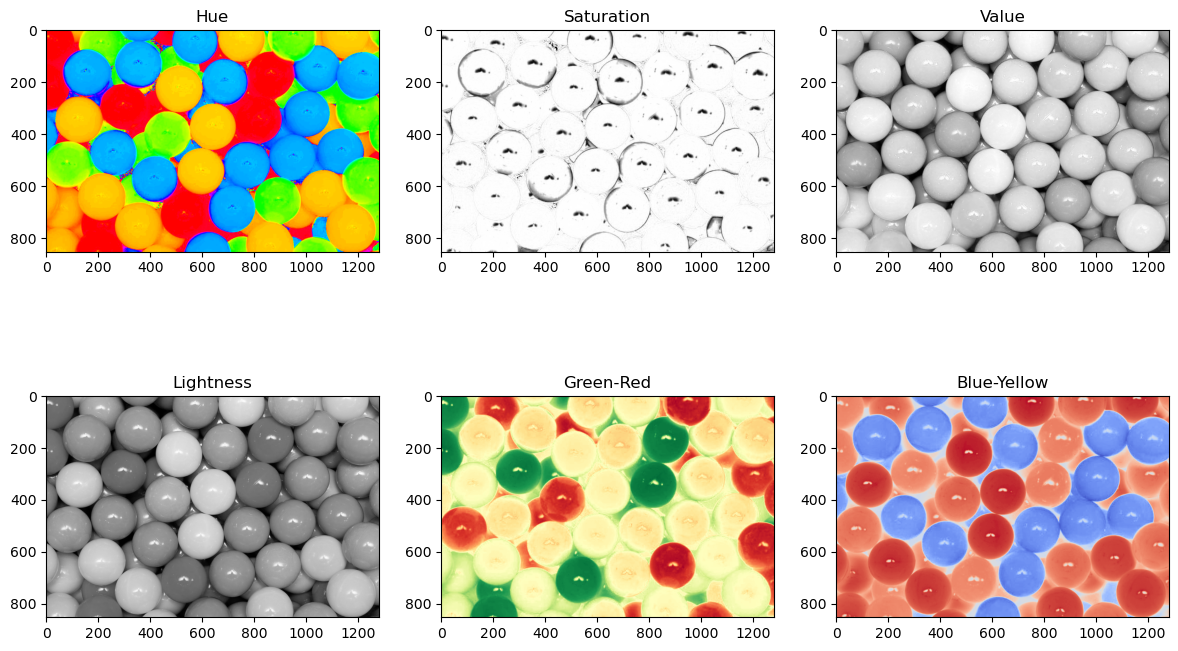

In [36]:
##########################################################
# 3. DISPLAY THE THREE CHANNELS OF EACH SPACE SIDE BY SIDE
##########################################################
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# HSV channels
axes[0,0].imshow(h, cmap='hsv'); axes[0,0].set_title("Hue")
axes[0,1].imshow(s, cmap='gray'); axes[0,1].set_title("Saturation")
axes[0,2].imshow(v, cmap='gray'); axes[0,2].set_title("Value")

# LAB channels
axes[1,0].imshow(l, cmap='gray'); axes[1,0].set_title("Lightness")
axes[1,1].imshow(a, cmap='RdYlGn'); axes[1,1].set_title("Green-Red")
axes[1,2].imshow(b, cmap='coolwarm'); axes[1,2].set_title("Blue-Yellow")

plt.tight_layout()
plt.show()

Hue: 98, Saturation: 255, Value: 235
Suggested range: lower=[88 50 50], upper=[108 255 255]


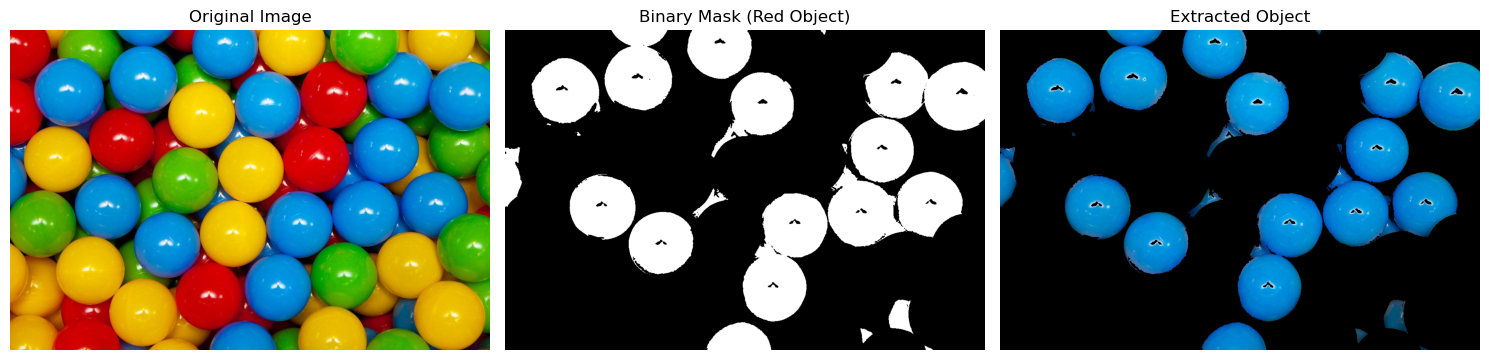

In [49]:
#####################################################################
# COLOUR PICKER
#####################################################################
lower_bound = None
upper_bound = None

def pick_color(event, x, y, flags, param):
    global lower_bound, upper_bound
    if event == cv2.EVENT_LBUTTONDOWN:
        hsv_value = hsv_image[y, x]
        hue = int(hsv_value[0])  # cast to Python int to avoid overflow
        sat = int(hsv_value[1])
        val = int(hsv_value[2])

        print(f"Hue: {hue}, Saturation: {sat}, Value: {val}")

        # Safe subtraction/addition with clamping
        lower_hue = max(0, hue - 10)
        upper_hue = min(179, hue + 10)

        # Suggested bounds
        lower_bound = np.array([lower_hue, 50, 50])
        upper_bound = np.array([upper_hue, 255, 255])

        print(f"Suggested range: lower={lower_bound}, upper={upper_bound}")

cv2.imshow('Select object', colourful_image_bgr)  # use BGR for OpenCV display
cv2.setMouseCallback('Select object', pick_color)
cv2.waitKey(0)
cv2.destroyAllWindows()


#masks
if lower_bound is not None and upper_bound is not None:
    mask = cv2.inRange(hsv_image, lower_bound, upper_bound)
    extracted_object = cv2.bitwise_and(colourful_image_rgb, colourful_image_rgb, mask=mask)


# Apply mask to extract the object
extracted_object_hsv = cv2.bitwise_and(hsv_image, hsv_image, mask=mask)
extracted_object_display = cv2.cvtColor(extracted_object_hsv, cv2.COLOR_HSV2RGB)
#axes[2].imshow(extracted_object_display)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(colourful_image_rgb)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Binary Mask (Red Object)')
axes[1].axis('off')

axes[2].imshow(extracted_object_display)
axes[2].set_title('Extracted Object')
axes[2].axis('off')

plt.tight_layout()
plt.show()


#### What it channel encodes
 HSV Channels:
1. Hue (S): Represents the pure color (0-180 in OpenCV, corresponding to 0-360 degrees), 
  where different angles correspond to different colors (red, green, blue, etc.).
2. Saturation (S): Represents the intensity or purity of the color, from 0 (gray) to maximum (pure color).
3. Value (V): Represents the brightness of the color, from 0 (black) to maximum (full brightness).

LAB Channels:
1. L (Lightness): Represents the brightness from black (0) to white (100).
2. a: Represents the color dimension from green (negative) to red (positive).
3. b: Represents the color dimension from blue (negative) to yellow (positive).

### Why HSV is easier for colour-based segmentation than RGB:

In RGB, a colour is defined by three values for Red, Green, Blue (RGB) that are all highly correlated with each other and with intensity changes. Even small 
variations in lighting or shadows can cause significant changes in all three RGB channels simultaneously. However, in HSV, the Hue channel encodes the 
actual colour independently of brightness and saturation. This means that regardless of lighting conditions, a red object will always have a similar
hue value (around 0° or 180°), making it much easier to define a consistent range for colour segmentation. A range can be set on the Hue
channel, while Saturation and Value handle the intensity variations.

## Task 2. Noise and smoothing - a controlled experiment (4 marks)

In [ ]:
##########################
# LOAD IMAGE AND CHANGE IT TO GRAYSCALE
##########################
colourful_image = cv2.imread('images/balls.jpg') 
colourful_image_rgb = cv2.cvtColor(colourful_image, cv2.COLOR_BGR2RGB)

## Task 3. Sharpening with unsharp masking (2 marks)

## Task 4. Edge detection three ways (4 marks).

## Task 5. Morphology: from mask to object count (3 marks).

## Task 6. Assemble a pipeline tool + reflection (2 marks).